# Lab 4 · Course Navigator
## Notebook 3 — Building our small Transformer

Module 6 develops the Transformer family and language-model training. Here we build an encoder for the same classification task used in Notebooks 1–2. The attention calculations carry across; the objective and masking choices follow the product we are building.

**Key question:** How can every token gather useful context without a recurrent time-step loop?

### Learning objectives
- Trace queries, keys, values, scaling, softmax and multiple heads.
- Distinguish padding masks from causal masks and classification from generation.
- Implement an encoder block, positional embeddings and masked pooling.
- Validate attention against PyTorch, train the model and inspect real attention maps.

### Classroom route and independent study

Plan about **50 minutes** for the guided route. Read the explanations, predict the output, then run each cell in order. Exercises and worked answers support a slower independent review. Saved results come from real CPU runs; seeds reduce variation but cannot guarantee identical numbers across machines.

### Setup

Use Python 3.12 in a dedicated environment. Download the **complete project ZIP** from the repository, extract it, install `requirements.txt`, and select that environment as your Jupyter kernel. In Colab, the first cell clones the project when needed. If imports fail, run `%pip install -r /content/course-navigator/requirements.txt` after that clone, restart the runtime and rerun from the top. Training needs no API key or paid service. The bundled base checkpoint permits offline model loading after dependencies are installed.

The default route loads supplied checkpoints. Set `RUN_TRAINING = True` to reproduce the full run into a separate classroom folder; the reference results remain unchanged. A notebook download alone does not contain its dataset and checkpoints.

In [1]:
from __future__ import annotations
from pathlib import Path
import sys, json, math, random, copy, time, re
from collections import Counter
from dataclasses import dataclass

# In Colab, clone the complete project once. Locally, open this notebook from
# the extracted project folder. A lone downloaded .ipynb has no model/data files.
ROOT = Path.cwd()
if not (ROOT / "coursenav").exists():
    if "google.colab" in sys.modules:
        import subprocess
        target = Path("/content/course-navigator")
        if not target.exists():
            subprocess.run(["git", "clone", "https://github.com/solomonpromise/course-navigator.git", str(target)], check=True)
        ROOT = target
    else:
        raise FileNotFoundError("Open this notebook inside the complete Course Navigator project folder; see README.md.")
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
# Optional progress widgets do not affect training.
warnings.filterwarnings("ignore", message="IProgress not found.*")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
from IPython.display import display, Markdown
from coursenav.data import LABELS, MAX_LENGTH, words, encode, load_records, fit_vocabulary, TextDataset
from coursenav.training import (TrainConfig, seed_everything, fit, logits_for, summarize,
    dataset_for, load_reference, pretrained_tokenizer, pretrained_dataset, make_model)
seed_everything(42)
train, validation, test = (load_records(split) for split in ["train", "validation", "test"])
vocabulary = json.loads((ROOT / "artifacts/vocabulary.json").read_text())
results = json.loads((ROOT / "artifacts/results.json").read_text())["models"]
RUN_TRAINING = False  # True runs training; False loads the supplied measured checkpoint.
print("PyTorch:", torch.__version__, "| Device: CPU | Maximum tokens:", MAX_LENGTH)
print("Passages:", len(train), "train /", len(validation), "validation /", len(test), "test")

PyTorch: 2.14.1 | Device: CPU | Maximum tokens: 96
Passages: 1201 train / 286 validation / 265 test


## 1. Match the architecture to the objective

Our task is **sequence classification**: read a complete question or passage, then predict a course topic. An encoder may use both earlier and later tokens. A next-token language model has a different objective and must hide future tokens during prediction.

Our small Transformer is randomly initialized and learns only from the course training split. It has two blocks, width 64 and four heads. It is deliberately small enough to inspect on a CPU. It does not have the language experience of a pretrained encoder.

Recall Notebook 2’s bottleneck: recurrent updates carry information through time. Self-attention instead constructs direct token-to-token connections. That shortens the path between distant tokens but does not guarantee better performance on a small dataset.

## 2. Queries, keys and values are learned projections

For each input vector x, three linear projections create a **query** q, **key** k and **value** v. Queries and keys determine relevance; values carry the information being combined.

$$A=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}+M\right),\qquad O=AV.$$

Each row of A distributes one query’s weight across allowed keys. The square-root scaling keeps dot-product magnitudes from growing simply because the head dimension grows. The mask M assigns a large negative score to disallowed keys before softmax.

These are learned computations, not human-supplied explanations. A high attention weight is not a causal proof that a word determined the prediction.

In [2]:
# Small invented numbers let us check the arithmetic before using learned weights.
q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
k = torch.tensor([[1., 0.], [1., 1.], [0., 1.]])
v = torch.tensor([[2., 0.], [0., 3.], [1., 1.]])
scores = q @ k.T / math.sqrt(q.shape[-1])
weights = scores.softmax(-1)
output = weights @ v
display(pd.DataFrame(scores.numpy()).round(3))
display(pd.DataFrame(weights.numpy()).round(3))
print("Each attention row sums to:", weights.sum(-1))
print("Mixed values:", output)

,0,1,2
0,0.707,0.707,0.000
1,0.000,0.707,0.707
2,0.707,1.414,0.707


,0,1,2
0,0.401,0.401,0.198
1,0.198,0.401,0.401
2,0.248,0.503,0.248


Each attention row sums to: tensor([1., 1., 1.])
Mixed values: tensor([[1.0000, 1.4011],
        [0.7967, 1.6044],
        [0.7448, 1.7587]])


## 3. Two masks, two different reasons

A **padding mask** prevents real tokens from reading artificial PAD keys. A **causal mask** prevents position t from reading future positions. For this encoder, every real token may read every other real token; only padding keys are hidden.

Why do we mask keys rather than merely zeroing PAD embeddings? A zero vector can still receive attention probability, and learned projections can add biases. Why exclude padded query outputs from pooling? A padded query can still read real keys and become nonzero. Both issues must be handled.

The causal example below connects to Module 6’s generative models. Applying this triangular mask alone would not turn our classifier into a trained language model: we would also need a vocabulary-sized output head, shifted token targets and next-token loss.

In [3]:
causal = torch.ones(3, 3, dtype=torch.bool).tril()
causal_weights = scores.masked_fill(~causal, -1e4).softmax(-1)
print("Encoder attention:", weights.round(decimals=3))
print("Causal attention:", causal_weights.round(decimals=3))
assert torch.equal(causal_weights.triu(1), torch.zeros_like(causal_weights))

Encoder attention: tensor([[0.4010, 0.4010, 0.1980],
        [0.1980, 0.4010, 0.4010],
        [0.2480, 0.5030, 0.2480]])
Causal attention: tensor([[1.0000, 0.0000, 0.0000],
        [0.3300, 0.6700, 0.0000],
        [0.2480, 0.5030, 0.2480]])


## 4. Implement multi-head attention

With width D=64 and H=4 heads, each head receives 16 components. We project Q/K/V, reshape `(B,T,D)` into `(B,H,T,D/H)`, compute per-head attention, then concatenate the head outputs and project again.

Each head has learned projection parameters; it is not assigned a fixed role such as “grammar” or “meaning.” Inspecting a head may suggest patterns, but these labels need evidence.

Attention creates a `(B,H,T,T)` score tensor. Doubling T approximately quadruples that tensor’s size. This is one reason to limit sequence length and batch size. Training can compute the token interactions in parallel; autoregressive generation still has sequential token-generation dependencies.

In [4]:
class SelfAttention(nn.Module):
    """Implement multi-head scaled dot-product attention explicitly.

    This encoder can inspect the entire input question. Padding keys are masked;
    there is no causal mask because we are not predicting the next token.
    """
    def __init__(self, width: int = 64, heads: int = 4):
        super().__init__()
        if width % heads:
            raise ValueError("Embedding width must divide evenly into heads")
        self.heads, self.head_width = heads, width // heads
        self.qkv = nn.Linear(width, 3 * width)
        self.output = nn.Linear(width, width)
        self.dropout = nn.Dropout(0.1)

    def forward(self, x: torch.Tensor, mask: torch.Tensor, inspect: bool = False):
        batch, length, width = x.shape
        # Separate projections, then (B,T,D) -> (B,H,T,D/H).
        q, k, v = [part.reshape(batch, length, self.heads, self.head_width).transpose(1, 2)
                   for part in self.qkv(x).chunk(3, dim=-1)]
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_width)
        scores = scores.masked_fill(~mask[:, None, None, :], -1e4)
        weights = scores.softmax(dim=-1)  # each query distributes weight across valid keys
        mixed = self.dropout(weights) @ v
        mixed = mixed.transpose(1, 2).reshape(batch, length, width)
        output = self.output(mixed)
        return (output, weights) if inspect else output

In [5]:
seed_everything()
attention = SelfAttention(width=64, heads=4).eval()
x = torch.randn(2, 7, 64)
mask = torch.tensor([[1,1,1,1,0,0,0], [1,1,1,1,1,1,1]], dtype=torch.bool)
actual, maps = attention(x, mask, inspect=True)
q, k, v = [part.reshape(2,7,4,16).transpose(1,2) for part in attention.qkv(x).chunk(3,-1)]
reference = nn.functional.scaled_dot_product_attention(q, k, v,
    attn_mask=mask[:,None,None,:], dropout_p=0.0)
reference = attention.output(reference.transpose(1,2).reshape(2,7,64))
assert torch.allclose(actual, reference, atol=1e-6)
assert float(maps[0,:,:,4:].abs().max().detach()) == 0.0
print("Maximum implementation/reference difference:", float((actual-reference).abs().max().detach()))

Maximum implementation/reference difference: 8.940696716308594e-08


## 5. Build a block around attention

The **residual connection** adds a layer’s update to its input, preserving a direct information and gradient path. **Layer normalization** rescales a token’s feature components using learned scale and bias. Our block normalizes before each sublayer, a pre-normalization design.

The **feed-forward network** expands each token from D to 4D, applies GELU, then projects back. Its weights are shared across token positions; it does not itself mix tokens. Attention does the token mixing.

**Dropout** randomly suppresses selected activations during training. It is disabled at inference. Normalization, residuals and dropout have distinct jobs; none can repair poor data or a leaking evaluation.

In [6]:
class EncoderBlock(nn.Module):
    """Mix tokens with attention, then transform each token with an MLP.

    Pre-normalization and residual additions stabilize the update path. The
    feed-forward network uses the same parameters independently at each token.
    """
    def __init__(self, width: int = 64):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(width), nn.LayerNorm(width)
        self.attention = SelfAttention(width)
        self.ffn = nn.Sequential(nn.Linear(width, 4 * width), nn.GELU(),
                                 nn.Dropout(0.1), nn.Linear(4 * width, width))
        self.dropout = nn.Dropout(0.1)

    def forward(self, x, mask):
        x = x + self.dropout(self.attention(self.norm1(x), mask))
        return x + self.dropout(self.ffn(self.norm2(x)))

## 6. Positions and a sequence-level decision

Attention by itself does not encode order. We add a learned positional vector to each word embedding. A position table has an explicit maximum length; truncation and the exported inference contract must respect it.

After two blocks, **masked mean pooling** averages real token states into one vector. The head maps that vector to topic logits. We exclude PAD outputs even though PAD keys were already masked. A `[CLS]`-based head is another design; our mean-pooling choice is fixed before evaluation.

In [7]:
class TinyTransformer(nn.Module):
    """A two-block encoder built from the explicit attention implementation."""
    def __init__(self, vocabulary_size: int, width: int = 64):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, width, padding_idx=0)
        self.position = nn.Embedding(MAX_LENGTH, width)
        self.blocks = nn.ModuleList([EncoderBlock(width) for _ in range(2)])
        self.norm = nn.LayerNorm(width)
        self.head = nn.Linear(width, len(LABELS))

    def forward(self, ids, lengths):
        mask = ids.ne(0)
        positions = torch.arange(ids.shape[1], device=ids.device)
        x = self.embedding(ids) + self.position(positions)[None, :, :]
        for block in self.blocks:
            x = block(x, mask)
        # Mean only over real tokens; padding vectors must not dilute the mean.
        pooled = (self.norm(x) * mask[:, :, None]).sum(1) / mask.sum(1, keepdim=True)
        return self.head(pooled)

In [8]:
seed_everything()
transformer = TinyTransformer(len(vocabulary))
transformer.load_state_dict(torch.load(ROOT / "artifacts/transformer.pt", map_location="cpu", weights_only=True))
transformer.eval()
print("Parameters:", sum(p.numel() for p in transformer.parameters()))
batch = next(iter(DataLoader(TextDataset(validation, vocabulary), batch_size=4)))
with torch.inference_mode():
    prediction = transformer(batch[0], batch[1])
print("Output shape:", tuple(prediction.shape))
assert prediction.shape == (4, len(LABELS))

Parameters: 483846
Output shape: (4, 6)


## 7. Train with the same learning contract

Token IDs select embeddings; positions are added; attention and feed-forward blocks build context; pooling produces a sequence representation; the head emits logits. Cross-entropy compares logits with known topics. Backpropagation updates all trainable components, including embeddings and positions.

The reference loop and optimizer are the same as Notebook 1. The models have different parameter counts and optimization behavior, so equal epochs do not imply equal computation or a perfectly controlled study.

In [9]:
if RUN_TRAINING:
    seed_everything()
    transformer, history, seconds = fit(TinyTransformer(len(vocabulary)),
        TextDataset(train, vocabulary), TextDataset(validation, vocabulary), TrainConfig())
    output = ROOT / "artifacts/classroom"; output.mkdir(exist_ok=True)
    torch.save(transformer.state_dict(), output / "transformer.pt")
record = next(row for row in results if row["name"] == "transformer")
display(pd.DataFrame(record["history"]))

,epoch,train_loss,validation_macro_f1,validation_loss
0,1,1.754868,0.329221,1.649868
1,2,1.348746,0.460821,1.191282
2,3,0.932995,0.541172,1.146172
3,4,0.663495,0.541615,1.216952
4,5,0.483371,0.609227,1.104974
5,6,0.322902,0.627266,1.277542
6,7,0.196505,0.638442,1.559417
7,8,0.094465,0.623129,1.571161
8,9,0.074179,0.610336,1.941258
9,10,0.037080,0.621883,2.076595


## 8. Inspect an actual attention map

The figure below uses learned weights from the saved scratch Transformer. A row answers “where did this query gather values in this head?” Different heads and layers can differ. The map is an internal measurement, not a full explanation of the final prediction.

Try a sentence about a different topic, trace it through the same layer and compare. Keep the model in evaluation mode so dropout does not randomly alter the map.

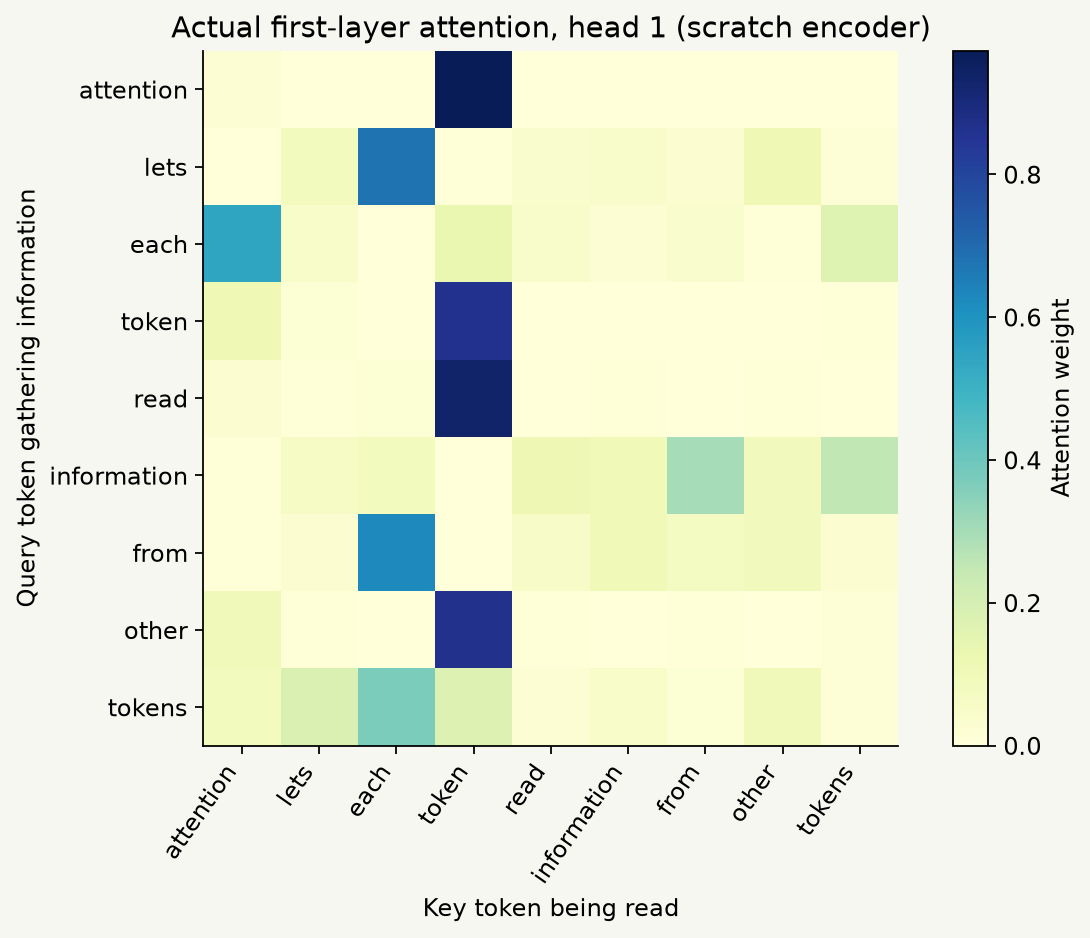

*First block, first head. Padding columns are excluded from this display.*

In [10]:
text = "attention lets each token read information from other tokens"
ids, length = encode(text, vocabulary)
input_ids = torch.tensor([ids]); mask = input_ids.ne(0)
with torch.inference_mode():
    x = transformer.embedding(input_ids) + transformer.position(torch.arange(MAX_LENGTH))[None,:,:]
    _, attention_maps = transformer.blocks[0].attention(transformer.blocks[0].norm1(x), mask, inspect=True)
print("Attention tensor:", tuple(attention_maps.shape))
print("Real-key row sums:", attention_maps[0,0,:length,:length].sum(-1))

Attention tensor: (1, 4, 96, 96)
Real-key row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


## 9. What this run establishes

Our scratch encoder reaches about **0.523 passage test macro-F1**, compared with about 0.669 at its best validation epoch. The validation/test gap matters. It is evidence that a single validation score can overstate the generalization we later observe.

The result exceeds this simple RNN’s score, but it does not prove that attention universally beats recurrence. The encoder also differs in pooling, parameterization and depth. The TF-IDF baseline remains stronger on this dataset. More data, different architectures and repeated seeds would be new experiments, requiring careful validation and fresh held-out assessment if we repeatedly develop against the current test.

**Check yourself.**

1. Why does padding masking not remove the need for masked pooling?
2. What changes if we apply a causal mask to a complete question?
3. What else must change to train next-token generation?
4. Why does more attention capacity not guarantee better test performance?

<details><summary>Worked answers</summary>

1. Padded queries can gather real values and become nonzero; pooling must still exclude their outputs.
2. Earlier positions lose access to later context. This changes the information available to the encoder and needs a deliberate objective/architecture decision.
3. Predict token-vocabulary logits at every position, shift targets, mask future tokens and padding appropriately, and train a language-model objective. Generation then appends sampled or selected tokens step by step.
4. Capacity can fit training details the test does not share. Data quality, supervision, optimization, regularization and evaluation design remain decisive.

</details>

**Next:** [Notebook 4 — Adapting a pretrained Transformer](04_pretrained.ipynb). We reuse representations learned from a much larger language corpus.